# 4. Lower spectrum: uniform and random local initialization

Clean version of the current experiment. Run cells from top to bottom. Original notebooks are unchanged.

The factor $q_0=1-\delta/((d-1)\Delta)$ is a limiting local reference, not a proved finite-region or global error bound.


This experiment uses 256 independent runs per ensemble in the quick profile (500 in full), 20,000 global iterations, and 5,000 local iterations. We retain the three fixed spectra and compare:
1. uniform initialization on the full sphere;
2. independently randomized initialization inside $\mathcal E_{\eta,\delta}$;
3. the same global runs aligned at their first entrance into that region.

For local starts, draw a unit vector $w$ uniformly in $u_1^\perp$, a random sign $s$,
and $U\sim\mathrm{Unif}(0,1)$. Set $e=U\eta\delta$ and
$$L(w)=\sum_{i=2}^d(\lambda_1-\lambda_i)w_i^2,\qquad
 v^0=s\sqrt{1-e/L(w)}\,u_1+\sqrt{e/L(w)}\,w.$$
Then $\varepsilon_0=e\le\eta\delta$. This is a specified random local distribution,
**not uniform surface measure on the entire error sublevel set**. Reusing $U,w,s$
across spectra gives the same initial errors and transverse directions, although
angles depend on the spectrum. Global initial vectors are identical across spectra.
The Gaussian search draws are coupled across spectra and initialization modes;
runs within each ensemble are independent.

All fits use the negative least-squares slope of the log arithmetic mean on the
normalized error window $[10^{-4},0.5]$. Fits to the global curve mix entrance and
contraction and are descriptive, not local-theorem rates. First-entry comparisons
include **every run** and use a common horizon after the latest entry in each ensemble.
If any run has not entered, the post-entry fit is explicitly omitted rather than
selecting only successful runs. Error curves and pointwise 95% bootstrap intervals
use complete-trajectory resampling. For normalized curves, each bootstrap mean is
divided by its own bootstrapped initial mean.


In [1]:
# Imports, configuration, and reproducible initialization.
from pathlib import Path
import json, csv, sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

from operator_norm import diagonal_ensemble, rate_constants

RANDOM_PROFILE = 'quick'  # quick: 256 runs / 200 resamples; full: 500 / 500
HERE = Path.cwd()
RANDOM_D = 100
RANDOM_GAP = 0.1
RANDOM_ETAS = [0.01, 0.1, 0.5]
RANDOM_STEPS = 5000  # local runs and maximum post-entry horizon
RANDOM_GLOBAL_STEPS = 20000
RANDOM_SEED = 20261029
RANDOM_RUNS, RANDOM_BOOTSTRAP = {'quick': (256,200), 'full': (500,500)}[RANDOM_PROFILE]
RANDOM_WINDOW = (1e-4, .5)
RANDOM_CACHE = HERE / 'results' / '03_random_initialization' / RANDOM_PROFILE
RANDOM_OUT = HERE / 'results' / '03_random_initialization' / RANDOM_PROFILE
RANDOM_OUT.mkdir(parents=True, exist_ok=True)
random_spectra = {
    'Spread': np.r_[1., np.linspace(1-RANDOM_GAP,0.,RANDOM_D-1)],
    'Clustered at second': np.r_[1.,np.full(RANDOM_D-2,1-RANDOM_GAP),0.],
    'Clustered at zero': np.r_[1.,1-RANDOM_GAP,np.zeros(RANDOM_D-2)],
}
random_eta_colors = ['#0072B2','#D55E00','#009E73']
random_spectrum_colors = ['#0072B2','#D55E00','#009E73']
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm',
                     'axes.grid':True,'grid.alpha':.18,'figure.dpi':110,
                     'savefig.dpi':180,'pdf.fonttype':42})
rng = np.random.default_rng(RANDOM_SEED)
global_initial = rng.normal(size=(RANDOM_RUNS,RANDOM_D))
global_initial /= np.linalg.norm(global_initial,axis=1)[:,None]
local_w = rng.normal(size=(RANDOM_RUNS,RANDOM_D))
local_w[:,0]=0.
local_w /= np.linalg.norm(local_w,axis=1)[:,None]
local_u = rng.uniform(size=RANDOM_RUNS)
local_sign = rng.choice([-1.,1.],size=RANDOM_RUNS)
random_results = {}

def random_fit(E, seed):
    mean = E.mean(axis=0)
    ratio = mean/mean[0]
    eligible = np.flatnonzero((ratio>=RANDOM_WINDOW[0]) & (ratio<=RANDOM_WINDOW[1]))
    used = eligible[np.unique(np.linspace(0,len(eligible)-1,min(400,len(eligible)),dtype=int))] if len(eligible) else eligible
    answer = dict(rate=np.nan,low=np.nan,high=np.nan,first=None,last=None,points=len(used))
    if len(used)<10: return answer
    centered = used-used.mean()
    denom = centered@centered
    weights = np.random.default_rng(seed).multinomial(len(E),np.full(len(E),1/len(E)),size=RANDOM_BOOTSTRAP)
    boot = weights@E[:,used]/len(E)
    boot_rates = -(np.log(np.maximum(boot,np.finfo(float).tiny))@centered)/denom
    answer.update(rate=float(-(np.log(mean[used])@centered)/denom),
                  low=float(np.quantile(boot_rates,.025)),high=float(np.quantile(boot_rates,.975)),
                  first=int(used[0]),last=int(used[-1]))
    return answer


In [2]:
# Run each global ensemble once; eta only changes its entrance threshold.
for case,(name,lam) in enumerate(random_spectra.items()):
    path = RANDOM_CACHE / f'case{case}_global_d{RANDOM_D}_g{RANDOM_GAP:g}_N{RANDOM_RUNS}_K{RANDOM_GLOBAL_STEPS}_seed{RANDOM_SEED}.npz'
    if path.exists():
        with np.load(path) as z:
            np.testing.assert_allclose(z['lambdas'],lam)
            global_E=z['errors']
    else:
        global_E=diagonal_ensemble(lam,runs=RANDOM_RUNS,steps=RANDOM_GLOBAL_STEPS,
            seed=RANDOM_SEED+1,initial=global_initial,eta=RANDOM_ETAS[0])['errors']
        np.savez_compressed(path,errors=global_E,lambdas=lam,initial=global_initial)
    assert global_E.shape==(RANDOM_RUNS,RANDOM_GLOBAL_STEPS+1)
    random_results[name]={'global':global_E,'local':{},'entry':{},'hits':{}}
    print(f'{name}: global ensemble ready',flush=True)
    for eta in RANDOM_ETAS:
        target=local_u*eta*RANDOM_GAP
        transverse_error=np.sum((lam[0]-lam)*local_w**2,axis=1)
        radial=target/transverse_error
        local_initial=local_w*np.sqrt(radial)[:,None]
        local_initial[:,0]=local_sign*np.sqrt(1-radial)
        np.testing.assert_allclose(np.linalg.norm(local_initial,axis=1),1.,atol=1e-12)
        np.testing.assert_allclose(np.sum((lam[0]-lam)*local_initial**2,axis=1),target,rtol=1e-12)
        path=RANDOM_CACHE/f'case{case}_local_eta{eta:g}_d{RANDOM_D}_g{RANDOM_GAP:g}_N{RANDOM_RUNS}_K{RANDOM_STEPS}_seed{RANDOM_SEED}.npz'
        if path.exists():
            with np.load(path) as z:
                np.testing.assert_allclose(z['lambdas'],lam)
                local_E=z['errors']
        else:
            local_E=diagonal_ensemble(lam,runs=RANDOM_RUNS,steps=RANDOM_STEPS,
                seed=RANDOM_SEED+1,initial=local_initial,eta=eta)['errors']
            np.savez_compressed(path,errors=local_E,lambdas=lam,initial=local_initial,eta=eta)
        np.testing.assert_allclose(local_E[:,0],target,rtol=1e-12)
        assert np.all(local_E[:,0]<=eta*RANDOM_GAP)
        assert np.all(np.isfinite(local_E)) and np.all(local_E>=0)
        assert np.max(np.diff(local_E,axis=1))<1e-11
        random_results[name]['local'][eta]=local_E
        entered=global_E<=eta*RANDOM_GAP
        hits=np.where(entered.any(axis=1),entered.argmax(axis=1),-1)
        random_results[name]['hits'][eta]=hits
        if np.all(hits>=0):
            horizon=min(RANDOM_STEPS,RANDOM_GLOBAL_STEPS-int(hits.max()))
            aligned=global_E[np.arange(RANDOM_RUNS)[:,None],hits[:,None]+np.arange(horizon+1)]
            assert np.all(aligned[:,0]<=eta*RANDOM_GAP)
        else:
            aligned=None
        random_results[name]['entry'][eta]=aligned
        print(f'  eta={eta:g}: entered {np.sum(hits>=0)}/{RANDOM_RUNS}; '
              f'post-entry horizon={aligned.shape[1]-1 if aligned is not None else "omitted (censored)"}',flush=True)
random_rows=[]
for case,(name,lam) in enumerate(random_spectra.items()):
    item=random_results[name]
    for eta in RANDOM_ETAS:
        c=rate_constants(lam,eta)
        theory=-np.log1p(-c['delta']/((RANDOM_D-1)*c['width']))
        for mode,E in [('Global',item['global']),('Random local',item['local'][eta]),('After entry',item['entry'][eta])]:
            fit=random_fit(E,RANDOM_SEED+200+case) if E is not None else dict(rate=np.nan,low=np.nan,high=np.nan,first=None,last=None,points=0)
            random_rows.append(dict(spectrum=name,eta=eta,mode=mode,**fit,
                local_theory=theory if mode!='Global' else np.nan,
                censored_runs=int(np.sum(item['hits'][eta]<0)),
                median_entry=float(np.median(item['hits'][eta])) if np.all(item['hits'][eta]>=0) else np.nan,
                max_entry=int(item['hits'][eta].max()),
                horizon=E.shape[1]-1 if E is not None else 0))
with (RANDOM_OUT/'rate_comparison.csv').open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(random_rows[0]));writer.writeheader();writer.writerows(random_rows)
(RANDOM_OUT/'configuration.json').write_text(json.dumps(dict(
    d=RANDOM_D,gap=RANDOM_GAP,runs=RANDOM_RUNS,local_steps=RANDOM_STEPS,global_steps=RANDOM_GLOBAL_STEPS,
    etas=RANDOM_ETAS,seed=RANDOM_SEED,bootstrap=RANDOM_BOOTSTRAP,fit_window=RANDOM_WINDOW,
    local_distribution='uniform transverse direction, uniform target error in (0,eta*delta), random leading sign',
    post_entry='all runs; common horizon after latest entry; omit if censored'),indent=2))


Spread: global ensemble ready
  eta=0.01: entered 256/256; post-entry horizon=5000
  eta=0.1: entered 256/256; post-entry horizon=5000
  eta=0.5: entered 256/256; post-entry horizon=5000
Clustered at second: global ensemble ready
  eta=0.01: entered 256/256; post-entry horizon=5000
  eta=0.1: entered 256/256; post-entry horizon=5000
  eta=0.5: entered 256/256; post-entry horizon=5000
Clustered at zero: global ensemble ready
  eta=0.01: entered 256/256; post-entry horizon=5000
  eta=0.1: entered 256/256; post-entry horizon=5000
  eta=0.5: entered 256/256; post-entry horizon=5000


415

## Spectrum-colored comparison: uniform sphere starts versus fresh random local starts

The **left** panel uses uniform initialization on the whole sphere. The **right**
uses freshly sampled random vectors inside $\mathcal E_{\eta,\delta}$, from the
random-local experiment above. It does not reuse first-entry states from the global runs.

The figure retains serif/Computer Modern-style text, blue/orange/green spectrum colors, framed axes, and a light grid. Solid curves show arithmetic mean error divided by the ensemble initial mean. Each panel has one shared gray dashed reference $q_0^k$. It is a limiting local reference, not a guaranteed error envelope for these starts.

The default shading is pointwise 95% trajectory-bootstrap uncertainty for the
normalized mean, with each bootstrap mean divided by its own starting mean.
A companion export shows mean ± one sample standard deviation, divided by the
observed ensemble's initial mean, to describe variability between runs.
The fresh-local sampling distribution is specified above and is not uniform
surface measure over the whole local error region.

The comparison figure uses $\eta=0.1$. Its single shared theoretical local-rate curve is gray. The separate ratio plot below includes all three eta values for the randomized local initialization.

All displayed comparison references now use q0=1-delta/((d-1)Delta). It is a limiting local reference, not a guaranteed upper bound for finite-error local or global starts; eta=0 itself corresponds to exact maximizers. Initialization eta=0.1 and the empirical curves are unchanged.


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


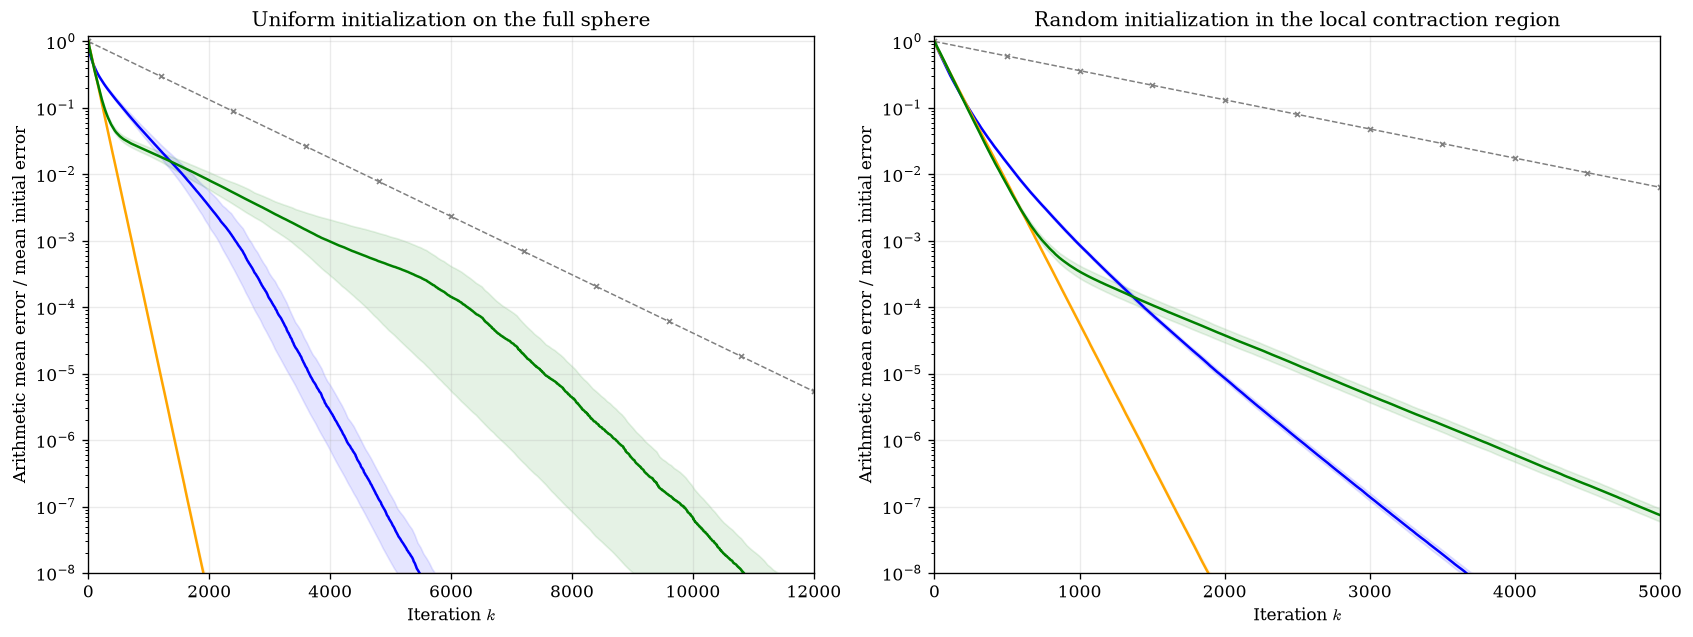

In [3]:
COMPARISON_ETA = 0.1
COMPARISON_BAND = 'bootstrap'  # 'bootstrap' or 'std'
COMPARISON_LOCAL_HORIZON = RANDOM_STEPS
COMPARISON_GLOBAL_HORIZON = min(RANDOM_GLOBAL_STEPS,12000)
COMPARISON_COLORS = ['blue', 'orange', 'green']
COMPARISON_FLOOR = 1e-8
assert COMPARISON_ETA in RANDOM_ETAS
assert COMPARISON_BAND in ('bootstrap','std')
# Match the original notebook's plotting setup, including framed axes.
plt.rcParams.update({
    'font.size':10, 'font.family':'serif',
    'font.serif':['Computer Modern Roman','DejaVu Serif'],
    'mathtext.fontset':'cm','axes.unicode_minus':False,
    'figure.dpi':120,'savefig.dpi':200,'axes.grid':True,'grid.alpha':.25,
    'axes.spines.top':True,'axes.spines.right':True,
    'axes.spines.bottom':True,'axes.spines.left':True,
})

def spectrum_start_comparison(band):
    fig,axes=plt.subplots(1,2,figsize=(14,5.2),layout='constrained')
    summary=[]
    for case,((name,lam),color) in enumerate(zip(random_spectra.items(),COMPARISON_COLORS)):
        item=random_results[name]
        local_E=item['local'][COMPARISON_ETA][:,:COMPARISON_LOCAL_HORIZON+1]
        global_E=item['global'][:,:COMPARISON_GLOBAL_HORIZON+1]
        c=rate_constants(lam,COMPARISON_ETA)
        logq0=np.log1p(-c['delta']/((RANDOM_D-1)*c['width']))
        assert np.all(local_E[:,0]<=COMPARISON_ETA*c['delta'])
        summary.append(dict(spectrum=name,q0=float(np.exp(logq0)),mean_local_initial=float(local_E[:,0].mean()),
                            mean_global_initial=float(global_E[:,0].mean()),runs=len(local_E)))
        for ax,E in zip(axes,[global_E,local_E]):
            k=np.arange(E.shape[1])
            idx=np.unique(np.linspace(0,len(k)-1,min(250,len(k)),dtype=int))
            e0=E[:,0].mean()
            mean=E.mean(axis=0)/e0
            if band=='bootstrap':
                weights=np.random.default_rng(RANDOM_SEED+400+case).multinomial(
                    len(E),np.full(len(E),1/len(E)),size=RANDOM_BOOTSTRAP)
                boot=weights@E[:,idx]/len(E)
                boot/=boot[:,0:1]
                low,high=np.quantile(boot,[.025,.975],axis=0)
            else:
                std=E[:,idx].std(axis=0,ddof=1)/e0
                low,high=mean[idx]-std,mean[idx]+std
            ax.semilogy(k,mean,color=color,linestyle='-',linewidth=1.5)
            ax.fill_between(idx,np.maximum(low,COMPARISON_FLOOR),
                            np.maximum(high,COMPARISON_FLOOR),color=color,alpha=.10)
            if case==0:  # one shared limiting local reference, eta=0
                ax.semilogy(k,np.exp(logq0*k),color='gray',linestyle='--',
                            marker='x',markevery=max(1,len(k)//10),markersize=3,linewidth=.9)
    axes[0].set(title='Uniform initialization on the full sphere',
                xlabel='Iteration $k$',ylabel='Arithmetic mean error / mean initial error',
                xlim=(0,COMPARISON_GLOBAL_HORIZON),ylim=(COMPARISON_FLOOR,1.2))
    axes[1].set(title='Random initialization in the local contraction region',
                xlabel='Iteration $k$',ylabel='Arithmetic mean error / mean initial error',
                xlim=(0,COMPARISON_LOCAL_HORIZON),ylim=(COMPARISON_FLOOR,1.2))
    from matplotlib.patches import Patch
    handles=[Line2D([],[],color=color,label=name) for name,color in zip(random_spectra,COMPARISON_COLORS)]
    handles += [Line2D([],[],color='black',linestyle='-',label='Empirical mean'),
                Line2D([],[],color='gray',linestyle='--',marker='x',markersize=3,
                       linewidth=.9,label=r'Limiting local reference $q_0^k$'),
                Patch(facecolor='gray',alpha=.15,label='95% bootstrap interval' if band=='bootstrap' else 'Mean ± one sample std')]
    tag=f'spectrum_global_vs_local_gray_eta{COMPARISON_ETA:g}_{band}'
    fig.savefig(RANDOM_OUT/f'{tag}.pdf',bbox_inches='tight')
    fig.savefig(RANDOM_OUT/f'{tag}.png',bbox_inches='tight')
    with (RANDOM_OUT/f'spectrum_global_vs_local_gray_eta{COMPARISON_ETA:g}_constants.csv').open('w',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(summary[0]));writer.writeheader();writer.writerows(summary)
    return fig

other_band='std' if COMPARISON_BAND=='bootstrap' else 'bootstrap'
other_fig=spectrum_start_comparison(other_band)
plt.close(other_fig)
comparison_fig=spectrum_start_comparison(COMPARISON_BAND)
plt.show()


## Updated numerical table and rate-ratio plot for random local starts

The table reports $\eta=0.1$, $d=100$, $\delta=0.1$, $\Delta=1$, $N=256$ and
$K=5000$ for the **randomized local** initialization. The rate is a least-squares
fit of the log arithmetic mean on the normalized-mean error window $[10^{-4},0.5]$,
using at most 400 points. The ratio is $\widehat a/(-\log q_0)$ and the final
column is $\overline\varepsilon_{5000}/\overline\varepsilon_0$.
The exported LaTeX fragment uses booktabs, already present in the manuscript.

The ratio plot places the three spectral configurations on the x-axis, with the original spectrum colors. Solid/circle, dashed/square, and dotted/triangle identify eta=0.01, 0.1, and 0.5, respectively.
Error bars are pointwise 95% trajectory-bootstrap intervals for the fitted rate,
divided by the deterministic limiting local exponent. They condition on the fitting
window chosen from the original ensemble; they are not simultaneous intervals
or paired significance tests. The table describes fresh randomized local starts, not deterministic two-eigenvector starts.

The denominator a0=-log(q0) is common to all initialization eta values and spectra in this experiment. Consequently, ratios across eta now reflect only differences in the fitted empirical rates. The reference is not claimed to be the optimal algorithmic rate or a finite-error guarantee.


Random local starts, eta=0.1:
Spread                : rate=0.00590526, ratio=5.843, final relative mean=5.59745e-11
Clustered at second   : rate=0.00973108, ratio=9.629, final relative mean=5.4638e-22
Clustered at zero     : rate=0.00565717, ratio=5.598, final relative mean=7.44109e-08


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


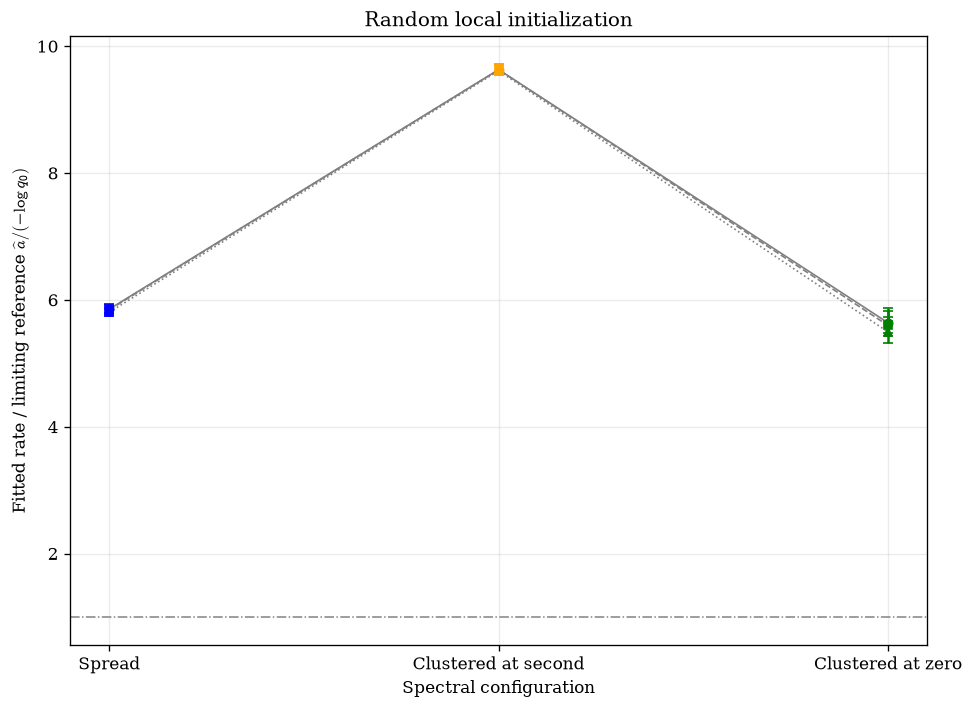

In [4]:
# Random-local table and ratio plot, using the exact same ensembles as the comparison figure.
ratio_records=[]
for case,(name,lam) in enumerate(random_spectra.items()):
    for eta in RANDOM_ETAS:
        E=random_results[name]['local'][eta]
        fit=random_fit(E,RANDOM_SEED+200+case)
        c=rate_constants(lam,eta)
        theory=-np.log1p(-c['delta']/((len(lam)-1)*c['width']))
        ratio_records.append(dict(spectrum=name,eta=eta,runs=len(E),iterations=E.shape[1]-1,
            fitted_rate=fit['rate'],rate_low=fit['low'],rate_high=fit['high'],
            reference_rate=theory,reference_eta=0,rate_ratio=fit['rate']/theory,
            ratio_low=fit['low']/theory,ratio_high=fit['high']/theory,
            final_relative_mean=float(E[:,-1].mean()/E[:,0].mean()),
            first_fit_iteration=fit['first'],last_fit_iteration=fit['last'],fit_points=fit['points']))
with (RANDOM_OUT/'random_local_rate_ratios.csv').open('w',newline='') as f:
    w=csv.DictWriter(f,fieldnames=list(ratio_records[0]));w.writeheader();w.writerows(ratio_records)
table_rows=[r for r in ratio_records if np.isclose(r['eta'],.1)]
with (RANDOM_OUT/'random_local_table_eta0.1.csv').open('w',newline='') as f:
    w=csv.DictWriter(f,fieldnames=list(table_rows[0]));w.writeheader();w.writerows(table_rows)
def sci_tex(value):
    exponent=int(np.floor(np.log10(abs(value))))
    return rf'{value/10.**exponent:.3f}\times10^{{{exponent}}}'
labels={'Spread':'Spread spectrum','Clustered at second':r'Clustered at $\lambda_2$',
        'Clustered at zero':r'Clustered at zero'}
lines=[r'\begin{table}[t]',r'\centering',r'\begin{tabular}{lrrr}',r'\toprule',
       r'Spectral configuration & Fitted rate & Ratio & $\bar\varepsilon_{5000}/\bar\varepsilon_0$ \\',r'\midrule']
for row in table_rows:
    lines.append(labels[row['spectrum']]+rf" & ${sci_tex(row['fitted_rate'])}$ & ${row['rate_ratio']:.2f}$ & ${sci_tex(row['final_relative_mean'])}$ \\")
lines += [r'\bottomrule',r'\end{tabular}',
    r'\caption{Random local initialization with $\eta=0.1$, $d=100$, $\delta=0.1$, and $\Delta=1$, using $256$ independent runs and $5000$ iterations. Rates are fitted to the logarithm of the arithmetic mean over relative errors in $[10^{-4},0.5]$. The ratio is the fitted rate divided by $-\log q_0$ (the limiting local reference).}',
    r'\label{tab:random-local-rates}',r'\end{table}']
(RANDOM_OUT/'random_local_table_eta0.1.tex').write_text('\n'.join(lines)+'\n')
print('Random local starts, eta=0.1:')
for r in table_rows:
    print(f"{r['spectrum']:22s}: rate={r['fitted_rate']:.6g}, ratio={r['rate_ratio']:.3f}, final relative mean={r['final_relative_mean']:.6g}")
# Original categorical layout: spectrum on x; styles and markers identify eta.
fig,ax=plt.subplots(figsize=(8,5.8),layout='constrained')
eta_styles={.01:'-',.1:'--',.5:':'}
eta_markers={.01:'o',.1:'s',.5:'^'}
colors=['blue','orange','green']
x=np.arange(len(random_spectra))
for eta in RANDOM_ETAS:
    records=[next(r for r in ratio_records if r['spectrum']==name and np.isclose(r['eta'],eta))
             for name in random_spectra]
    yy=np.array([r['rate_ratio'] for r in records])
    ax.plot(x,yy,color='gray',linestyle=eta_styles[eta],linewidth=1)
    for j,(r,color) in enumerate(zip(records,colors)):
        ax.errorbar(j,r['rate_ratio'],
            yerr=[[max(r['rate_ratio']-r['ratio_low'],0)],
                  [max(r['ratio_high']-r['rate_ratio'],0)]],
            color=color,marker=eta_markers[eta],markersize=5,linestyle='none',capsize=3)
ax.axhline(1,color='gray',linestyle='-.',linewidth=.9)
ax.set_xticks(x,['Spread','Clustered at second','Clustered at zero'])
ax.set(xlabel='Spectral configuration',
       ylabel=r'Fitted rate / limiting reference $\widehat a/(-\log q_0)$',
       title='Random local initialization')
handles=[Line2D([],[],color='gray',linestyle=eta_styles[eta],marker=eta_markers[eta],
                label=rf'$\eta={eta:g}$') for eta in RANDOM_ETAS]
handles.append(Line2D([],[],color='gray',linestyle='-.',label='Equal rates'))
fig.savefig(RANDOM_OUT/'random_local_rate_ratios.pdf',bbox_inches='tight')
fig.savefig(RANDOM_OUT/'random_local_rate_ratios.png',bbox_inches='tight')
plt.show()
